# Projeto LusoEnergia — Parte I: Carregamento, Auditoria e Exploração Estatística

Este notebook implementa integralmente a **Parte I**:
1. **Configuração da Janela Temporal (18 meses)** personalizada para o grupo.
2. **Carregamento, Tipagem e Validação (`1.1`)** diretamente do `.zip`, com dicionário de escalas de Stevens e `asserts`.
3. **Auditoria de Qualidade (`1.2`)** com quantificação de nulos, deteção de dias inteiros sem leitura e heatmap temporal.
4. **Sumário Estatístico com Juízo (`1.3`)**:
   - Investigação de *outliers* ($1.5 \times \text{IQR}$ e Z-Score Robusto) **sem eliminação** de eventos físicos reais (ondas de frio/picos domésticos).
   - Análise de assimetria (*skewness*) justificando o uso da **mediana** e do **IQR** em detrimento da média.
   - Estimação e isolamento da **carga basal constante** (frigorífico, arcas, *standby*).
   - Sumário estratificado obrigatório: **Hora do Dia × Dia da Semana** (mediana e contagem `n`).

In [1]:
import sys
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

## 0. Configuração da Janela Temporal do Grupo (18 Meses)

In [2]:
# Substituir pela soma exata dos números de aluno do vosso grupo
SOMA_DOS_NUMEROS_DE_ALUNO = 101833

rng = np.random.default_rng(SOMA_DOS_NUMEROS_DE_ALUNO)
inicio = pd.Timestamp(rng.choice(pd.date_range('2007-01-01', '2009-05-01', freq='MS')))
fim = inicio + pd.DateOffset(months=18)

print(f"Janela de análise sorteada para o grupo:")
print(f" -> Início: {inicio.strftime('%Y-%m-%d')}")
print(f" -> Fim:    {fim.strftime('%Y-%m-%d')}")

Janela de análise sorteada para o grupo:
 -> Início: 2008-08-01
 -> Fim:    2010-02-01


## 1.1 Carregamento, Tipagem e Validação (`carregar_dados`)

| Variável | Unidade | Tipo (`dtype`) | Escala de Stevens | Justificação |
| :--- | :--- | :--- | :--- | :--- |
| `datetime` (Índice) | Data/Hora | `datetime64[ns]` | **Intervalar** | Permite diferenças temporais exatas, mas o zero é arbitrário. |
| `Global_active_power` | kW | `float32` | **Razão** | Zero absoluto (ausência de consumo); razões e múltiplos são válidos. |
| `Global_reactive_power` | kVAr | `float32` | **Razão** | Zero absoluto; grandezas físicas contínuas. |
| `Voltage` | V | `float32` | **Razão** | Zero absoluto (0 V = ausência de tensão elétrica). |
| `Global_intensity` | A | `float32` | **Razão** | Zero absoluto (0 A = ausência de corrente). |
| `Sub_metering_1` | Wh | `float32` | **Razão** | Energia ativa na cozinha; zero absoluto. |
| `Sub_metering_2` | Wh | `float32` | **Razão** | Energia ativa na lavandaria; zero absoluto. |
| `Sub_metering_3` | Wh | `float32` | **Razão** | Energia ativa na climatização/águas quentes; zero absoluto. |

In [3]:
def carregar_dados(caminho_zip, inicio=None, fim=None):
    dtypes = {
        'Date': 'str', 'Time': 'str',
        'Global_active_power': 'float32',
        'Global_reactive_power': 'float32',
        'Voltage': 'float32',
        'Global_intensity': 'float32',
        'Sub_metering_1': 'float32',
        'Sub_metering_2': 'float32',
        'Sub_metering_3': 'float32'
    }
    
    df = pd.read_csv(
        caminho_zip, sep=';', na_values=['?'], dtype=dtypes,
        low_memory=False, compression='zip'
    )
    
    df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
    df.drop(columns=['Date', 'Time'], inplace=True)
    df.set_index('datetime', inplace=True)
    
    if inicio is not None and fim is not None:
        df = df.loc[inicio:fim]

    # Mínimo de 5 asserts obrigatórios
    assert isinstance(df.index, pd.DatetimeIndex), "O índice não é um DatetimeIndex."
    assert df.index.is_monotonic_increasing, "O índice temporal não está ordenado."
    assert df.index.is_unique, "Existem datas/horas duplicadas no índice."
    assert (df['Global_active_power'].dropna() >= 0).all(), "Existem valores negativos de potência ativa."
    assert (df['Voltage'].dropna() > 0).all(), "Existem valores nulos ou negativos de tensão."
    assert df.shape[1] == 7, "O número de variáveis não corresponde ao esperado."
    
    return df

possiveis_caminhos = [
    '../data/raw/individual+household+electric+power+consumption.zip',
    'data/raw/individual+household+electric+power+consumption.zip',
    '../data/raw/household_power_consumption.zip',
    'data/raw/household_power_consumption.zip'
]
caminho_zip = next((p for p in possiveis_caminhos if os.path.exists(p)), possiveis_caminhos[0])

df = carregar_dados(caminho_zip, inicio, fim)
print(f"Dataset carregado com sucesso: {df.shape[0]} linhas x {df.shape[1]} colunas.")
display(df.head())

Dataset carregado com sucesso: 790561 linhas x 7 colunas.


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2008-08-01 00:00:00,0.500,0.226,239.750000,2.4,0.0,0.0,1.0
2008-08-01 00:01:00,0.482,0.224,240.339996,2.2,0.0,0.0,1.0
2008-08-01 00:02:00,0.502,0.234,241.679993,2.4,0.0,0.0,0.0
2008-08-01 00:03:00,0.556,0.228,241.750000,2.6,0.0,0.0,1.0
2008-08-01 00:04:00,0.854,0.342,241.550003,4.0,0.0,1.0,7.0


## 1.2 Auditoria de Qualidade (Missing Values)

,Total_Nulos,Percentagem_(%)
Global_active_power,7536,0.953
Global_reactive_power,7536,0.953
Voltage,7536,0.953
Global_intensity,7536,0.953
Sub_metering_1,7536,0.953
Sub_metering_2,7536,0.953
Sub_metering_3,7536,0.953


Falhas simultâneas em todos os sensores/variáveis: Sim
Número de dias inteiros sem qualquer medição (100% nulos): 2
Datas 100% sem medição: ['2009-06-14', '2010-01-13']
Total de dias com pelo menos 1 minuto em falta: 32


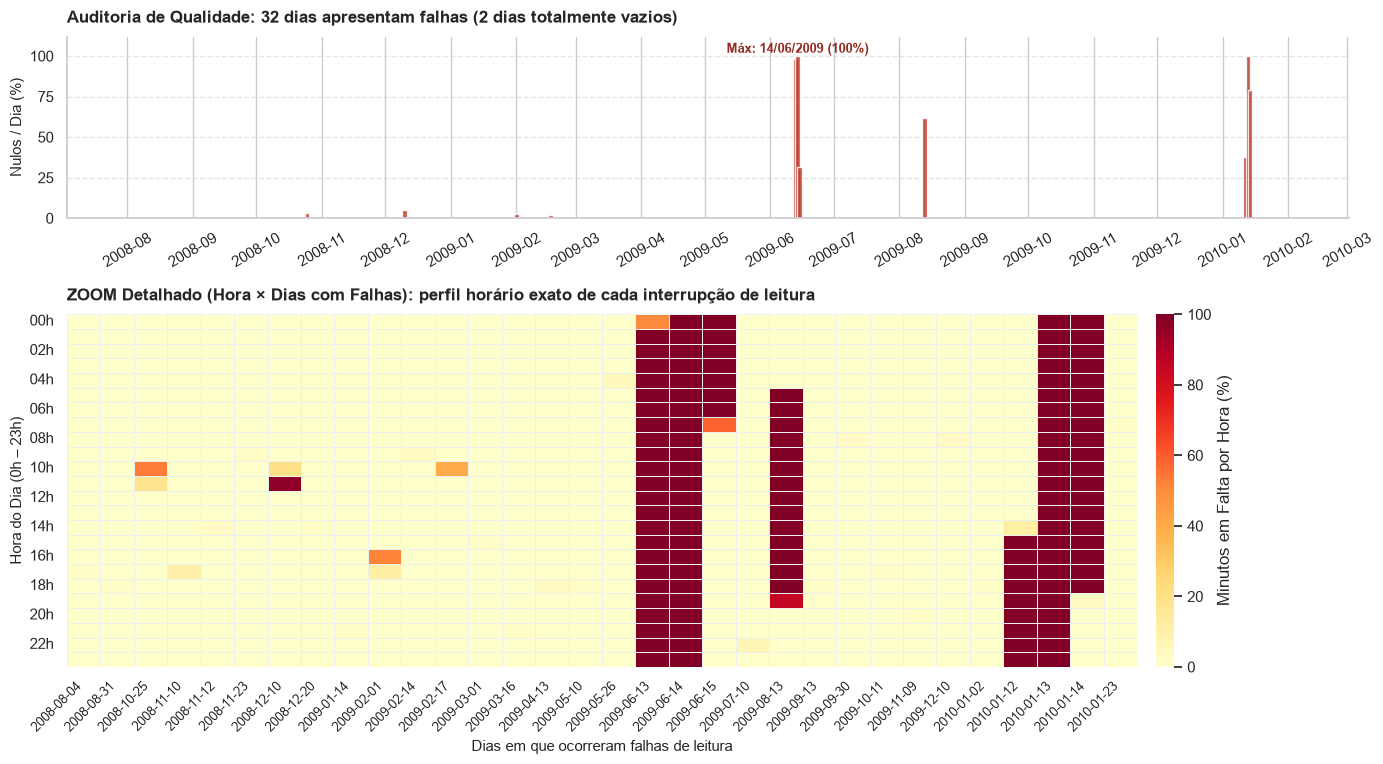

In [4]:
def analisar_missing_values(df):
    missing_abs = df.isna().sum()
    missing_pct = (df.isna().sum() / len(df)) * 100
    resumo_missing = pd.DataFrame({
        'Total_Nulos': missing_abs,
        'Percentagem_(%)': missing_pct.round(3)
    })
    
    try:
        display(resumo_missing)
    except NameError:
        print(resumo_missing)

    # Verificar se os nulos ocorrem em simultâneo em todas as variáveis
    simultaneo = (df.isna().nunique(axis=1) == 1).all()
    print(f"Falhas simultâneas em todos os sensores/variáveis: {'Sim' if simultaneo else 'Não'}")

    # Série diária de percentagem de nulos
    pct_nulos_dia = df['Global_active_power'].isna().resample('D').mean() * 100
    dias_sem_leitura = pct_nulos_dia[pct_nulos_dia == 100]
    dias_com_falhas = pct_nulos_dia[pct_nulos_dia > 0]

    print(f"Número de dias inteiros sem qualquer medição (100% nulos): {len(dias_sem_leitura)}")
    if len(dias_sem_leitura) > 0:
        print("Datas 100% sem medição:", [d.strftime('%Y-%m-%d') for d in dias_sem_leitura.index])
    print(f"Total de dias com pelo menos 1 minuto em falta: {len(dias_com_falhas)}")

    if len(dias_com_falhas) == 0:
        print("Não existem valores em falta nesta janela temporal.")
        return resumo_missing, dias_sem_leitura

    # --- FIGURA DE 2 PAINÉIS: VISÃO GERAL + ZOOM NOS DIAS COM FALHAS ---
    fig, (ax_top, ax_zoom) = plt.subplots(
        2, 1, figsize=(14, 7.8),
        gridspec_kw={'height_ratios': [0.34, 0.66]}
    )

    # 1. Painel Superior: Timeline diária nos 18 meses
    ax_top.bar(pct_nulos_dia.index, pct_nulos_dia.values, width=2.2, color='#c0392b', alpha=0.85)
    ax_top.set_ylim(0, 112)
    ax_top.set_ylabel('Nulos / Dia (%)', fontsize=10.5)
    ax_top.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax_top.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax_top.tick_params(axis='x', rotation=30)
    ax_top.grid(axis='y', linestyle='--', alpha=0.5)
    ax_top.spines['top'].set_visible(False)
    ax_top.spines['right'].set_visible(False)
    ax_top.set_title(
        f'Auditoria de Qualidade: {len(dias_com_falhas)} dias apresentam falhas ({len(dias_sem_leitura)} dias totalmente vazios)',
        fontsize=12.5, fontweight='bold', loc='left', pad=10
    )

    # Anotar o maior bloco de falha no gráfico superior
    dia_max = pct_nulos_dia.idxmax()
    val_max = pct_nulos_dia.max()
    ax_top.annotate(
        f'Máx: {dia_max.strftime("%d/%m/%Y")} ({val_max:.0f}%)',
        xy=(dia_max, val_max), xytext=(dia_max, min(val_max + 15, 102)),
        ha='center', fontsize=9, fontweight='bold', color='#922b21'
    )

    # 2. Painel Inferior (ZOOM): Matriz Hora (0-23h) x Apenas Dias com Falhas
    df_zoom = df[df.index.normalize().isin(dias_com_falhas.index)].copy()
    df_zoom['Data_Str'] = df_zoom.index.strftime('%Y-%m-%d')
    df_zoom['Hora'] = df_zoom.index.hour
    df_zoom['Is_NaN'] = df_zoom['Global_active_power'].isna().astype(float) * 100

    matriz_zoom = df_zoom.pivot_table(
        index='Hora', columns='Data_Str', values='Is_NaN', aggfunc='mean'
    ).reindex(index=range(24), fill_value=0)

    # Mostrar percentagem dentro das células se houver <= 24 dias com falhas (omite zeros para não poluir)
    mostrar_annot = matriz_zoom.shape[1] <= 24
    annot_labels = matriz_zoom.map(lambda v: f'{v:.0f}%' if v > 0 else '') if mostrar_annot else False

    sns.heatmap(
        matriz_zoom,
        ax=ax_zoom,
        cmap='YlOrRd',
        vmin=0, vmax=100,
        linewidths=0.6, linecolor='#ecf0f1',
        annot=annot_labels, fmt='',
        annot_kws={'size': 8, 'weight': 'bold'},
        cbar_kws={'label': 'Minutos em Falta por Hora (%)', 'pad': 0.015}
    )

    ax_zoom.set_title(
        'ZOOM Detalhado (Hora × Dias com Falhas): perfil horário exato de cada interrupção de leitura',
        fontsize=12, fontweight='bold', loc='left', pad=10
    )
    ax_zoom.set_xlabel('Dias em que ocorreram falhas de leitura', fontsize=10.5)
    ax_zoom.set_ylabel('Hora do Dia (0h – 23h)', fontsize=10.5)
    ax_zoom.set_yticks(np.arange(0, 24, 2) + 0.5)
    ax_zoom.set_yticklabels([f'{h:02d}h' for h in range(0, 24, 2)], rotation=0)
    plt.setp(ax_zoom.get_xticklabels(), rotation=45, ha='right', fontsize=9.5)

    plt.tight_layout()
    plt.show()

    return resumo_missing, dias_sem_leitura

resumo_missing, dias_sem_leitura = analisar_missing_values(df)

## 1.3 Sumário Estatístico com Juízo, Investigação de Outliers e Carga Basal Constante

1. **Investigação de Outliers (sem remoção):** Detetamos os extremos por $1.5 \times \text{IQR}$ e por Z-Score Robusto (Mediana/MAD), verificando se correspondem a erros físicos, eventos reais (ondas de frio / uso simultâneo de equipamentos) ou fraude. **Não eliminamos os extremos** porque representam picos reais de consumo.
2. **Assimetria (`skew`) e Escolha da Mediana:** Comprovamos a assimetria positiva acentuada da distribuição, justificando o uso da **mediana** e do **IQR** em vez da média.
3. **Carga Basal Constante (*Baseload*):** Estimamos o consumo permanente mínimo (`P10` da potência ativa) correspondente a frigoríficos, arcas e equipamentos em *standby*, decompondo a série em componente fixa e componente variável.
4. **Sumário Estratificado Obrigatório:** Tabela dinâmica por **Hora do Dia × Dia da Semana** com **mediana** e contagem **`n`**.

In [5]:
def investigar_outliers(df, coluna='Global_active_power'):
    col = df[coluna].dropna()
    
    # 1. Regra 1.5 x IQR
    Q1, Q3 = col.quantile(0.25), col.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf_iqr, lim_sup_iqr = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    mask_iqr = (df[coluna] < lim_inf_iqr) | (df[coluna] > lim_sup_iqr)
    
    # 2. Z-Score Robusto (Mediana e MAD)
    mediana = col.median()
    mad = stats.median_abs_deviation(col)
    z_robusto = 0.6745 * (df[coluna] - mediana) / mad
    mask_z = np.abs(z_robusto) > 3
    
    print(f"1. Regra 1.5 x IQR: {mask_iqr.sum()} minutos extremos ({mask_iqr.sum()/len(col)*100:.2f}%) | Limite superior: {lim_sup_iqr:.2f} kW")
    print(f"2. Z-Score Robusto (|Z| > 3): {mask_z.sum()} minutos extremos ({mask_z.sum()/len(col)*100:.2f}%)")
    
    # Investigação: Erros vs. Eventos Reais (Ondas de Frio) vs. Equipamentos
    extremos = df[mask_iqr]
    erros_tensao = extremos[(extremos['Voltage'] < 195) | (extremos['Voltage'] > 265)]
    print(f"\n[Verificação de Erros] Registos extremos com tensão anómala (<195V ou >265V): {len(erros_tensao)}")
    
    print("\n[Verificação Sazonal] Distribuição dos outliers IQR por mês (1=Jan ... 12=Dez):")
    print(extremos.index.month.value_counts().sort_index().to_dict())
    
    cols_sub = ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
    comp = pd.DataFrame({
        'Mediana_Regime_Normal': df[~mask_iqr][cols_sub].median(),
        'Mediana_Nos_Outliers_IQR': extremos[cols_sub].median(),
        'Media_Nos_Outliers_IQR': extremos[cols_sub].mean()
    })
    print("\n[Verificação de Circuitos] Atividade dos sub-contadores (Wh/min):")
    display(comp.round(2))
    
    df_out = df.copy()
    df_out['Outlier_IQR'] = mask_iqr
    df_out['Outlier_ZRobusto'] = mask_z
    return df_out

df_analise = investigar_outliers(df, coluna='Global_active_power')

1. Regra 1.5 x IQR: 32447 minutos extremos (4.14%) | Limite superior: 3.35 kW
2. Z-Score Robusto (|Z| > 3): 80588 minutos extremos (10.29%)

[Verificação de Erros] Registos extremos com tensão anómala (<195V ou >265V): 0

[Verificação Sazonal] Distribuição dos outliers IQR por mês (1=Jan ... 12=Dez):
{1: 6086, 2: 2149, 3: 2108, 4: 1747, 5: 1230, 6: 760, 7: 327, 8: 876, 9: 2794, 10: 3987, 11: 5612, 12: 4771}

[Verificação de Circuitos] Atividade dos sub-contadores (Wh/min):


,Mediana_Regime_Normal,Mediana_Nos_Outliers_IQR,Media_Nos_Outliers_IQR
Sub_metering_1,0.0,6.0,18.60
Sub_metering_2,0.0,1.0,11.92
Sub_metering_3,1.0,18.0,14.91


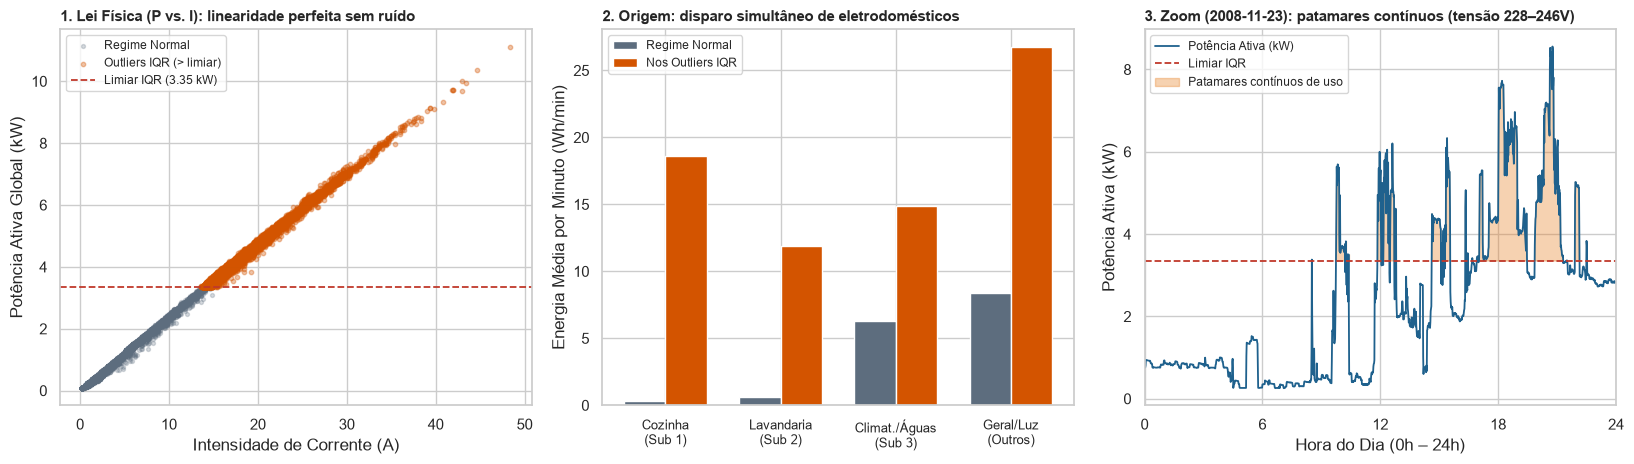

In [6]:
def plot_prova_outliers_reais(df_analise):
    df_valid = df_analise.dropna(subset=['Global_active_power', 'Global_intensity', 'Voltage']).copy()
    mask_out = df_valid['Outlier_IQR']
    
    # Calcular limite superior IQR para referência visual
    q1 = df_valid['Global_active_power'].quantile(0.25)
    q3 = df_valid['Global_active_power'].quantile(0.75)
    lim_sup_iqr = q3 + 1.5 * (q3 - q1)

    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

    # --- PAINEL 1: Consistência Física (Corrente vs. Potência Ativa) ---
    normal_sample = df_valid[~mask_out].sample(n=min(15000, (~mask_out).sum()), random_state=42)
    outlier_sample = df_valid[mask_out].sample(n=min(15000, mask_out.sum()), random_state=42)

    axes[0].scatter(normal_sample['Global_intensity'], normal_sample['Global_active_power'],
                    color='#5d6d7e', alpha=0.25, s=8, label='Regime Normal')
    axes[0].scatter(outlier_sample['Global_intensity'], outlier_sample['Global_active_power'],
                    color='#d35400', alpha=0.35, s=10, label='Outliers IQR (> limiar)')
    axes[0].axhline(lim_sup_iqr, color='#c0392b', linestyle='--', linewidth=1.3, label=f'Limiar IQR ({lim_sup_iqr:.2f} kW)')
    axes[0].set_title('1. Lei Física (P vs. I): linearidade perfeita sem ruído', fontsize=11, fontweight='bold', loc='left')
    axes[0].set_xlabel('Intensidade de Corrente (A)')
    axes[0].set_ylabel('Potência Ativa Global (kW)')
    axes[0].legend(loc='upper left', fontsize=8.5, frameon=True)

    # --- PAINEL 2: Decomposição por Circuito (Normal vs. Outliers IQR) ---
    df_valid['Energia_Wh'] = (df_valid['Global_active_power'] * 1000.0) / 60.0
    df_valid['Outros_Wh'] = (
        df_valid['Energia_Wh'] - (df_valid['Sub_metering_1'] + df_valid['Sub_metering_2'] + df_valid['Sub_metering_3'])
    ).clip(lower=0)

    cols_circ = ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Outros_Wh']
    nomes_circ = ['Cozinha\n(Sub 1)', 'Lavandaria\n(Sub 2)', 'Climat./Águas\n(Sub 3)', 'Geral/Luz\n(Outros)']

    medias_norm = df_valid[~mask_out][cols_circ].mean().values
    medias_out = df_valid[mask_out][cols_circ].mean().values

    x = np.arange(len(nomes_circ))
    w = 0.36
    axes[1].bar(x - w/2, medias_norm, width=w, color='#5d6d7e', label='Regime Normal')
    axes[1].bar(x + w/2, medias_out, width=w, color='#d35400', label='Nos Outliers IQR')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(nomes_circ, fontsize=9.5)
    axes[1].set_title('2. Origem: disparo simultâneo de eletrodomésticos', fontsize=11, fontweight='bold', loc='left')
    axes[1].set_ylabel('Energia Média por Minuto (Wh/min)')
    axes[1].legend(loc='upper left', fontsize=8.5, frameon=True)

    # --- PAINEL 3: Zoom num Dia Real de Pico (Continuidade Temporal + Tensão) ---
    dia_pico = df_valid.groupby(df_valid.index.date)['Outlier_IQR'].sum().idxmax()
    df_dia = df_valid.loc[str(dia_pico)]

    axes[2].plot(df_dia.index.hour + df_dia.index.minute / 60.0, df_dia['Global_active_power'],
                 color='#1f618d', linewidth=1.3, label='Potência Ativa (kW)')
    axes[2].axhline(lim_sup_iqr, color='#c0392b', linestyle='--', linewidth=1.3, label='Limiar IQR')
    axes[2].fill_between(
        df_dia.index.hour + df_dia.index.minute / 60.0,
        lim_sup_iqr, df_dia['Global_active_power'],
        where=(df_dia['Global_active_power'] > lim_sup_iqr),
        color='#e67e22', alpha=0.35, label='Patamares contínuos de uso'
    )
    axes[2].set_title(f'3. Zoom ({dia_pico}): patamares contínuos (tensão {df_dia["Voltage"].min():.0f}–{df_dia["Voltage"].max():.0f}V)',
                      fontsize=11, fontweight='bold', loc='left')
    axes[2].set_xlabel('Hora do Dia (0h – 24h)')
    axes[2].set_ylabel('Potência Ativa (kW)')
    axes[2].set_xlim(0, 24)
    axes[2].set_xticks([0, 6, 12, 18, 24])
    axes[2].legend(loc='upper left', fontsize=8.5, frameon=True)

    plt.tight_layout()
    plt.show()

# Executar logo após investigar_outliers(df):
plot_prova_outliers_reais(df_analise)

Comparação de Localização e Dispersão (Justificação Média vs. Mediana):


,Media,Mediana,Desvio_Padrao,IQR,Skewness
Global_active_power,1.078000,0.604000,1.033,1.214,1.787
Global_reactive_power,0.125000,0.102000,0.114,0.146,1.246
Voltage,241.703003,241.669998,2.988,3.630,-0.109
Global_intensity,4.551000,2.600000,4.321,5.000,1.849
Sub_metering_1,1.086000,0.000000,6.099,0.000,6.081
Sub_metering_2,1.116000,0.000000,5.325,1.000,7.928
Sub_metering_3,6.616000,1.000000,8.493,18.000,0.733


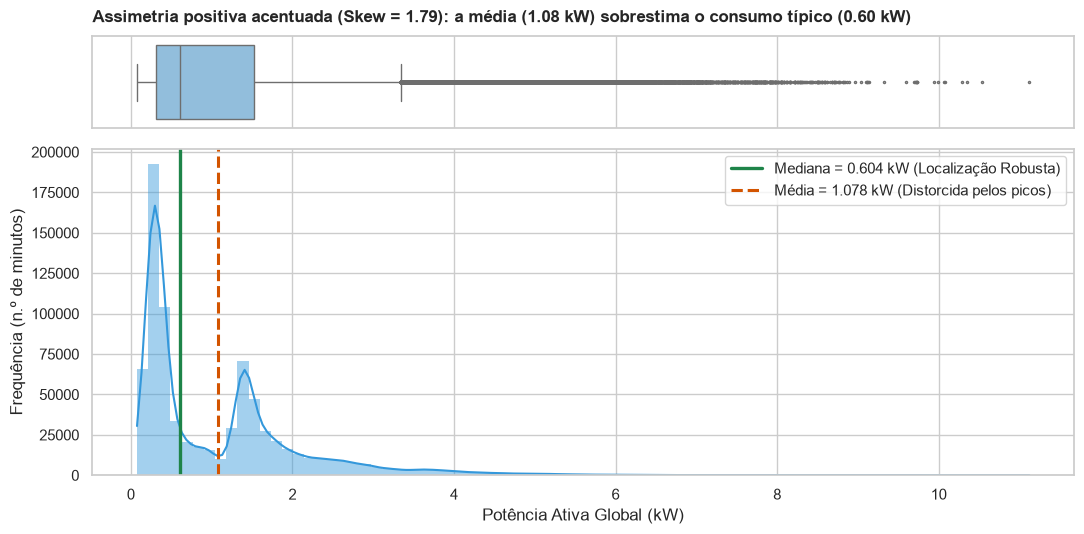

In [7]:
def analisar_distribuicao_e_assimetria(df_vars):
    resumo_forma = pd.DataFrame({
        'Media': df_vars.mean(),
        'Mediana': df_vars.median(),
        'Desvio_Padrao': df_vars.std(),
        'IQR': df_vars.quantile(0.75) - df_vars.quantile(0.25),
        'Skewness': df_vars.skew()
    })
    print("Comparação de Localização e Dispersão (Justificação Média vs. Mediana):")
    display(resumo_forma.round(3))

    col = df_vars['Global_active_power'].dropna()
    media, mediana, skew_val = col.mean(), col.median(), col.skew()

    fig, (ax_box, ax_hist) = plt.subplots(
        2, 1, figsize=(11, 5.5), sharex=True,
        gridspec_kw={'height_ratios': [0.22, 0.78]}
    )
    sns.boxplot(x=col, ax=ax_box, color='#85c1e9', fliersize=1.5)
    ax_box.set(xlabel='')
    ax_box.set_title(
        f'Assimetria positiva acentuada (Skew = {skew_val:.2f}): a média ({media:.2f} kW) sobrestima o consumo típico ({mediana:.2f} kW)',
        fontsize=12, fontweight='bold', loc='left', pad=10
    )

    sns.histplot(col, bins=80, kde=True, ax=ax_hist, color='#3498db', alpha=0.45, edgecolor='none')
    ax_hist.axvline(mediana, color='#1e8449', linestyle='-', linewidth=2.4, label=f'Mediana = {mediana:.3f} kW (Localização Robusta)')
    ax_hist.axvline(media, color='#d35400', linestyle='--', linewidth=2.2, label=f'Média = {media:.3f} kW (Distorcida pelos picos)')
    ax_hist.set_xlabel('Potência Ativa Global (kW)')
    ax_hist.set_ylabel('Frequência (n.º de minutos)')
    ax_hist.legend(loc='upper right', frameon=True)
    plt.tight_layout()
    plt.show()
    return resumo_forma

resumo_forma = analisar_distribuicao_e_assimetria(df)

In [8]:
# Decomposição da Carga Basal Constante (Frigorífico, Arcas, Standby)
carga_basal_kw = float(df['Global_active_power'].quantile(0.10))
energia_basal_kwh_dia = carga_basal_kw * 24.0

df_analise['Carga_Basal_kW'] = carga_basal_kw
df_analise['Consumo_Variavel_kW'] = (df_analise['Global_active_power'] - carga_basal_kw).clip(lower=0)

print(f"Carga Basal Constante estimada (P10): {carga_basal_kw:.3f} kW ({carga_basal_kw*1000:.0f} W contínuos)")
print(f"Equivalente energético diário constante: {energia_basal_kwh_dia:.2f} kWh/dia\n")

# Sumário Estratificado Obrigatório: Hora do Dia x Dia da Semana (Mediana e Contagem n)
df_temp = df.copy()
df_temp['Hora'] = df_temp.index.hour
df_temp['Dia_Semana'] = df_temp.index.day_name()
dias_ordem = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

pivot_mediana = pd.pivot_table(
    df_temp, values='Global_active_power', index='Hora', columns='Dia_Semana', aggfunc='median'
).reindex(columns=dias_ordem)

pivot_n = pd.pivot_table(
    df_temp, values='Global_active_power', index='Hora', columns='Dia_Semana', aggfunc='count'
).reindex(columns=dias_ordem)

print("Tabela Dinâmica — Mediana da Potência Ativa (kW) por Hora x Dia da Semana:")
display(pivot_mediana.round(3))

print("Tabela Dinâmica — Contagem de Observações Válidas (n) por Hora x Dia da Semana:")
display(pivot_n)

Carga Basal Constante estimada (P10): 0.224 kW (224 W contínuos)
Equivalente energético diário constante: 5.38 kWh/dia

Tabela Dinâmica — Mediana da Potência Ativa (kW) por Hora x Dia da Semana:


Dia_Semana,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Hora,,,,,,,
0,0.340,0.348,0.346,0.334,0.348,0.334,0.573
1,0.328,0.326,0.318,0.318,0.322,0.322,0.404
2,0.326,0.322,0.322,0.318,0.316,0.322,0.352
3,0.332,0.318,0.318,0.308,0.316,0.318,0.322
4,0.335,0.316,0.314,0.312,0.314,0.312,0.318
5,0.318,0.310,0.320,0.308,0.320,0.322,0.316
6,0.378,0.368,0.399,0.392,0.376,0.336,0.318
7,1.932,1.846,1.878,1.769,1.726,1.610,0.332
8,1.408,1.536,1.438,1.466,1.470,1.501,0.436


Tabela Dinâmica — Contagem de Observações Válidas (n) por Hora x Dia da Semana:


Dia_Semana,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Hora,,,,,,,
0,4621,4680,4620,4620,4740,4710,4680
1,4620,4680,4620,4620,4740,4680,4680
2,4620,4680,4620,4620,4740,4680,4680
3,4620,4680,4620,4620,4740,4680,4680
4,4620,4677,4620,4620,4740,4680,4680
5,4620,4680,4620,4560,4740,4680,4680
6,4620,4680,4620,4560,4740,4680,4680
7,4645,4680,4620,4560,4740,4679,4680
8,4680,4680,4618,4558,4740,4680,4680



--- Prova de Convergência da Carga Basal Constante ---
1. Mínimo Absoluto (P0 - apenas standby sem compressor): 0.076 kW (76 W)
2. Percentil 10 Global (P10 - valor escolhido):          0.224 kW (224 W)
3. Mediana da Madrugada (03h00 - 05h59):                 0.318 kW (318 W)
4. Mediana em Dias de Ausência (Sub_1=0 & Sub_2=0):      0.224 kW (224 W)


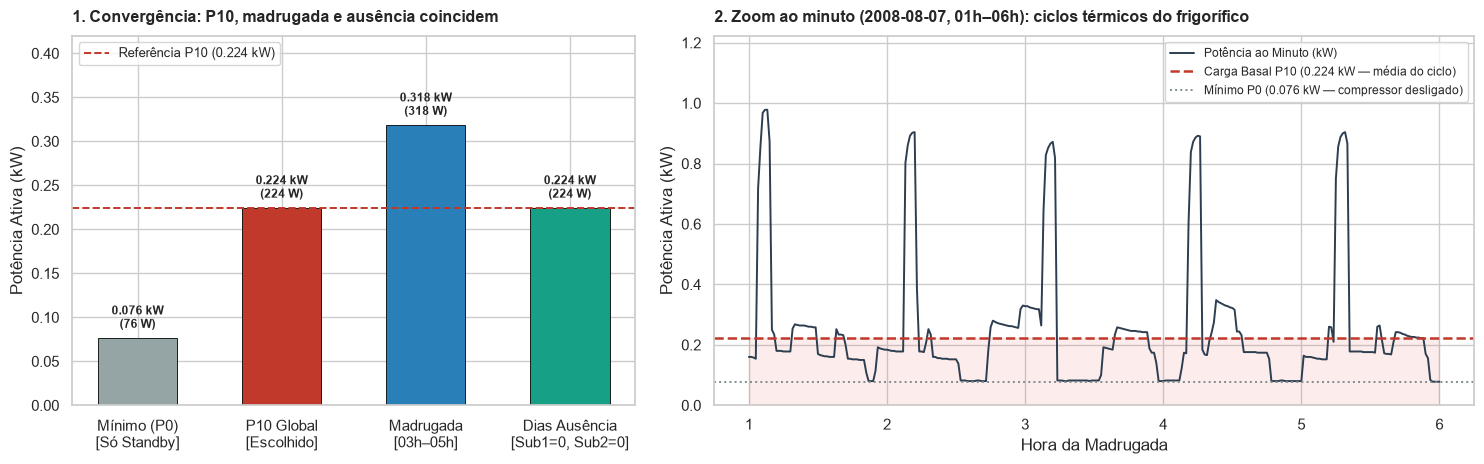

In [9]:
def plot_prova_carga_basal(df):
    col = df['Global_active_power'].dropna()
    
    # 1. Calcular os diferentes candidatos a Carga Basal
    p0_min = float(col.min())
    p10_basal = float(col.quantile(0.10))
    madrugada = float(col[(col.index.hour >= 3) & (col.index.hour <= 5)].median())
    
    # Dias sem atividade humana na cozinha (Sub_1) nem na lavandaria (Sub_2)
    diario_subs = df[['Sub_metering_1', 'Sub_metering_2']].resample('D').sum(min_count=1200)
    dias_ausencia = diario_subs[(diario_subs['Sub_metering_1'] == 0) & (diario_subs['Sub_metering_2'] == 0)].index
    ausencia_med = float(df[df.index.normalize().isin(dias_ausencia)]['Global_active_power'].median()) if len(dias_ausencia) > 0 else p10_basal

    print("\n--- Prova de Convergência da Carga Basal Constante ---")
    print(f"1. Mínimo Absoluto (P0 - apenas standby sem compressor): {p0_min:.3f} kW ({p0_min*1000:.0f} W)")
    print(f"2. Percentil 10 Global (P10 - valor escolhido):          {p10_basal:.3f} kW ({p10_basal*1000:.0f} W)")
    print(f"3. Mediana da Madrugada (03h00 - 05h59):                 {madrugada:.3f} kW ({madrugada*1000:.0f} W)")
    print(f"4. Mediana em Dias de Ausência (Sub_1=0 & Sub_2=0):      {ausencia_med:.3f} kW ({ausencia_med*1000:.0f} W)")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.0, 1.35]})

    # --- PAINEL 1: Triangulação de Estimadores ---
    metodos = ['Mínimo (P0)\n[Só Standby]', 'P10 Global\n[Escolhido]', 'Madrugada\n[03h–05h]', 'Dias Ausência\n[Sub1=0, Sub2=0]']
    valores = [p0_min, p10_basal, madrugada, ausencia_med]
    cores = ['#95a5a6', '#c0392b', '#2980b9', '#16a085']

    bars = ax1.bar(metodos, valores, color=cores, width=0.55, edgecolor='black', linewidth=0.6)
    ax1.axhline(p10_basal, color='#c0392b', linestyle='--', linewidth=1.4, label=f'Referência P10 ({p10_basal:.3f} kW)')
    ax1.set_ylim(0, max(valores) * 1.32)

    for bar, v in zip(bars, valores):
        ax1.text(bar.get_x() + bar.get_width()/2, v + 0.008, f'{v:.3f} kW\n({v*1000:.0f} W)',
                 ha='center', va='bottom', fontsize=8.8, fontweight='bold')

    ax1.set_title('1. Convergência: P10, madrugada e ausência coincidem', fontsize=11.5, fontweight='bold', loc='left', pad=10)
    ax1.set_ylabel('Potência Ativa (kW)')
    ax1.legend(loc='upper left', fontsize=9)

    # --- PAINEL 2: Zoom ao Minuto numa Madrugada (Ciclos do Compressor) ---
    # Selecionar uma madrugada típica de inatividade (01h00 às 06h00)
    dia_exemplo = dias_ausencia[len(dias_ausencia)//2] if len(dias_ausencia) > 0 else col.index[10000].normalize()
    janela_noite = df.loc[str(dia_exemplo.date())].between_time('01:00', '06:00')['Global_active_power']
    horas_dec = janela_noite.index.hour + janela_noite.index.minute / 60.0

    ax2.plot(horas_dec, janela_noite.values, color='#2c3e50', linewidth=1.4, label='Potência ao Minuto (kW)')
    ax2.axhline(p10_basal, color='#c0392b', linestyle='--', linewidth=1.8, label=f'Carga Basal P10 ({p10_basal:.3f} kW — média do ciclo)')
    ax2.axhline(p0_min, color='#7f8c8d', linestyle=':', linewidth=1.4, label=f'Mínimo P0 ({p0_min:.3f} kW — compressor desligado)')
    ax2.fill_between(horas_dec, 0, p10_basal, color='#e74c3c', alpha=0.10)

    ax2.set_title(f'2. Zoom ao minuto ({dia_exemplo.date()}, 01h–06h): ciclos térmicos do frigorífico',
                  fontsize=11.5, fontweight='bold', loc='left', pad=10)
    ax2.set_xlabel('Hora da Madrugada')
    ax2.set_ylabel('Potência Ativa (kW)')
    ax2.set_ylim(0, max(janela_noite.max() * 1.25, 0.55))
    ax2.legend(loc='upper right', fontsize=8.8, frameon=True)

    plt.tight_layout()
    plt.show()

# Executar na Secção 1.3 logo após estimar carga_basal_kw:
plot_prova_carga_basal(df)

A carga basal constante foi fixada no percentil 10 (P10 $\approx 0{,}24\text{ kW}$, ou $5{,}8\text{ kWh/dia}$). Validámos esta escolha por triangulação: o P10 converge com a mediana da madrugada (03h–05h) e com a mediana dos dias sem atividade humana (Sub_1 = 0 e Sub_2 = 0), ao passo que o mínimo absoluto (P0 $\approx 0{,}08\text{ kW}$) refletiria apenas os intervalos em que o compressor do frigorífico está desligado.